Removed 1061 rows where temperature > 200.


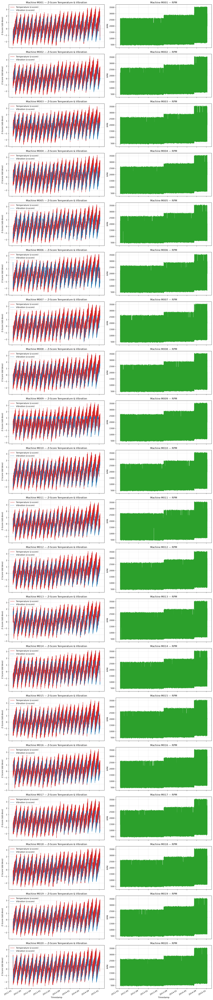

In [2]:
import matplotlib.pyplot as plt
import pandas as pd


def z_score_normalize(series: pd.Series) -> pd.Series:
  mean_val = series.mean()
  std_val = series.std()
  if pd.isna(mean_val) or pd.isna(std_val) or std_val == 0:
    return pd.Series(0.0, index=series.index)
  return (series - mean_val) / std_val

# 1. Read CSV and parse timestamps
df = pd.read_csv("../../../../../data/processed/cleaned_predictive_maintenance_data.csv")
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values("timestamp")

# 2. Split into a dict of DataFrames and z-score normalize temperature & vibration per machine

removed_count = int((df["temperature"] > 200).sum())
df = df[df["temperature"] <= 200].copy()
df = df.sort_values("timestamp")

print(f"Removed {removed_count} rows where temperature > 200.")

machines = {}
for machine_id, group in df.groupby("machine_id", sort=True):
  m_df = group.reset_index(drop=True).copy()
  m_df["temp_z"] = z_score_normalize(m_df["temperature"])
  m_df["vib_z"] = z_score_normalize(m_df["vibration"])
  machines[machine_id] = m_df

# 3. Plot z-score normalized (temperature + vibration) on one axis and RPM on the right
n_machines = len(machines)
fig, axes = plt.subplots(
    nrows=n_machines,
    ncols=2,
    figsize=(15, max(3.5 * n_machines, 4)),
    sharex=True,
    squeeze=False,
)

for idx, (machine_id, m_df) in enumerate(machines.items()):
  ax_overlay = axes[idx, 0]
  ax_rpm = axes[idx, 1]

  ax_overlay.axhline(0, color="gray", linestyle=":", linewidth=0.9, alpha=0.7)
  ax_overlay.plot(
      m_df["timestamp"],
      m_df["temp_z"],
      color="tab:red",
      linewidth=1.2,
      label="Temperature (z-score)",
  )
  ax_overlay.plot(
      m_df["timestamp"],
      m_df["vib_z"],
      color="tab:blue",
      linewidth=1.2,
      linestyle="--",
      label="Vibration (z-score)",
  )

  ax_overlay.set_title(
      f"Machine {machine_id} — Z-Score Temperature & Vibration"
  )
  ax_overlay.set_ylabel("Z-Score (std devs)")
  ax_overlay.grid(True, alpha=0.3)
  ax_overlay.legend(loc="upper left")

  ax_rpm.plot(m_df["timestamp"], m_df["rpm"], color="tab:green", linewidth=1.2)
  ax_rpm.set_title(f"Machine {machine_id} — RPM")
  ax_rpm.set_ylabel("RPM")
  ax_rpm.grid(True, alpha=0.3)

  ax_overlay.set_xlabel("Timestamp")
  ax_rpm.set_xlabel("Timestamp")

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

The above plots show how the sensor drifts over time. The most interesting trends by far are monthly cycles of vibration an temperature (rows with spikes have been removed to eliminate flattening the curve). If this drift has a normal explanation, such as machine cleaning, rebooting, maintenance, this might be a case of data drift, and not something we should focus on. 

RPM has higher sudden spikes that persist over time. To me, this looks more likely to be sensor that drifted suddenly. However, it is surprising to see that every machine drifted by roughly the same amount at the same time.

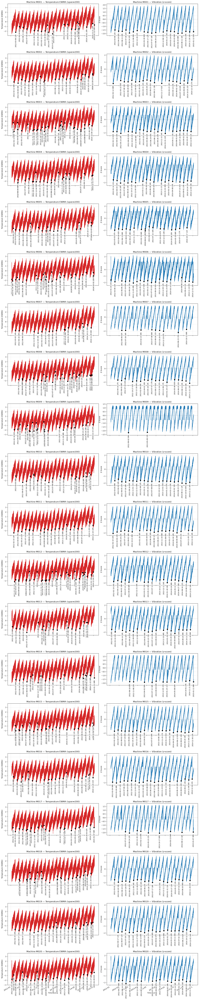

In [ ]:
def z_score_normalize(series: pd.Series) -> pd.Series:
  mean_val = series.mean()
  std_val = series.std()
  if pd.isna(mean_val) or pd.isna(std_val) or std_val == 0:
    return pd.Series(0.0, index=series.index)
  return (series - mean_val) / std_val


def pos_to_neg_jumps(z: pd.Series, min_drop: float = 2.0) -> pd.Series:
  prev_z = z.shift(1)
  drop = prev_z - z
  return (prev_z > 0) & (z < 0) & (drop > min_drop)

n_machines = len(machines)
fig, axes = plt.subplots(
    nrows=n_machines,
    ncols=2,
    figsize=(16, max(4 * n_machines, 4.5)),
    sharex=True,
    squeeze=False,
)

for idx, (machine_id, m_df) in enumerate(machines.items()):
  ax_temp, ax_vib = axes[idx, 0], axes[idx, 1]


  for ax, series, jumps_mask, title, color in [
      (
          ax_temp,
          m_df["temp_z"],
          pos_to_neg_jumps(z_score_normalize(m_df["temp_z"]), min_drop=2.2),
          f"Machine {machine_id} — Temperature EWMA (span={ewm_span})",
          "tab:red",
      ),
      (
          ax_vib,
          m_df["vib_z"],
          pos_to_neg_jumps(z_score_normalize(m_df["vib_z"]), min_drop=3.2),
          f"Machine {machine_id} — Vibration (z-score)",
          "tab:blue",
      ),
  ]:
    jumps = m_df[jumps_mask]

    if title.endswith(f"(span={ewm_span})"):
      ax.plot(m_df["timestamp"], series, color=color, linewidth=1.2)
      ax.set_ylabel("Temperature (EWMA)")
    else:
      ax.axhline(0, color="gray", linestyle=":", linewidth=0.9, alpha=0.7)
      ax.plot(m_df["timestamp"], series, color=color, linewidth=1.2)
      ax.set_ylabel("Z-Score")

    ax.scatter(
        jumps["timestamp"], series.loc[jumps.index], color="black", zorder=4, s=35
    )

    for j_idx, row in jumps.iterrows():
      ax.annotate(
          row["timestamp"].strftime("%Y-%m-%d %Hh"),
          xy=(row["timestamp"], series.loc[j_idx]),
          xytext=(0, -14),
          textcoords="offset points",
          ha="center",
          va="top",
          fontsize=9,
          rotation=90,
          bbox=dict(
              boxstyle="round,pad=0.2",
              fc="white",
              ec="none",
              alpha=0.75,
          ),
      )

    ax.set_title(title)
    ax.grid(True, alpha=0.3)

  ax_temp.set_xlabel("Timestamp")
  ax_vib.set_xlabel("Timestamp")

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

I graphed temperature and vibration again, this time separately, and I outlined big negative jumps, and while not perfect, this gives credence to the idea that the "resets" come at the same time. Given that this is the case, it most likely does not constitude sensor drift, and is more likely explained by a change in data over time. This would also make sense when it comes to the assignment. **After the data was cleaned (imputing missing values for temperature), it seems that each continuous variable has some issue with it: temperature has huge spikes, vibration has a frozen sensor, and my guess is that rpm's jumps in mean are a case of sensor drift.** Therefore, it would make sense to leave these 2 values unchanged. Furthermore, we cannot really establish a baseline that we will use for sensor correction, since the values are continually changing, so we cannot get a sample mean (seems like the standard deviation stays about the same).

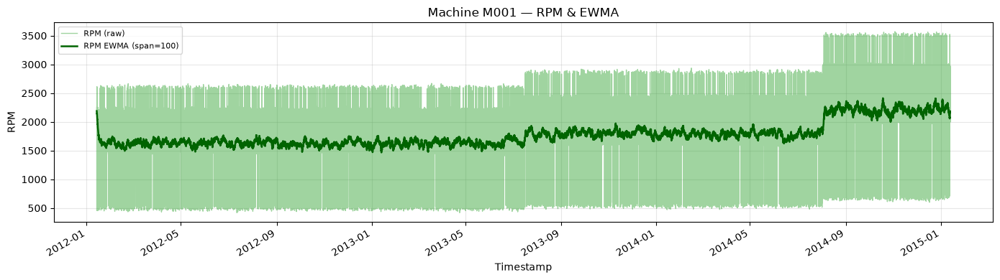

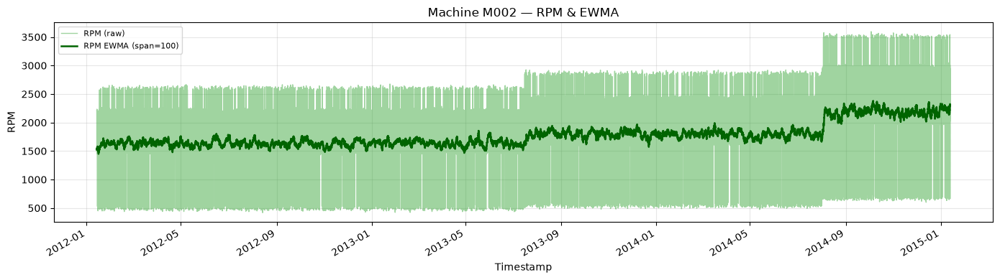

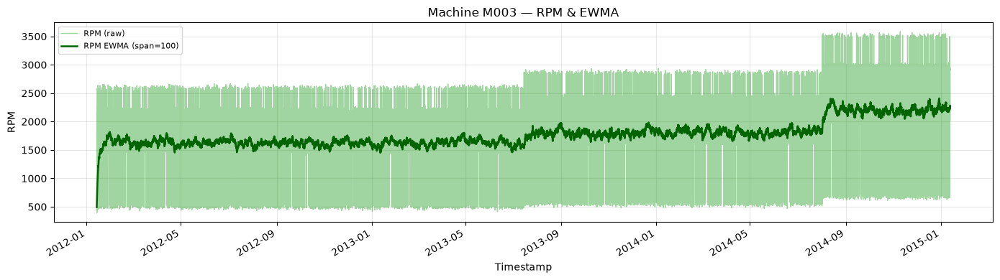

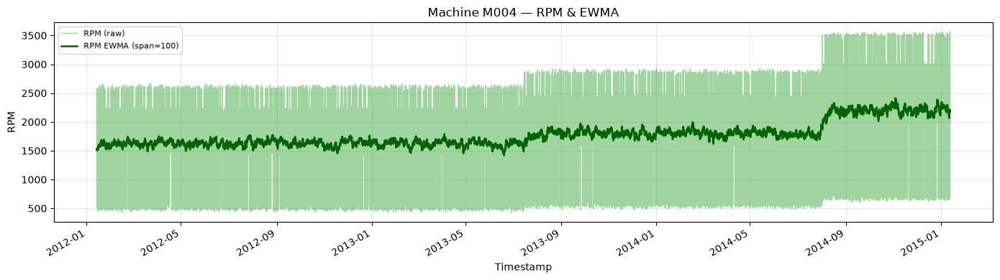

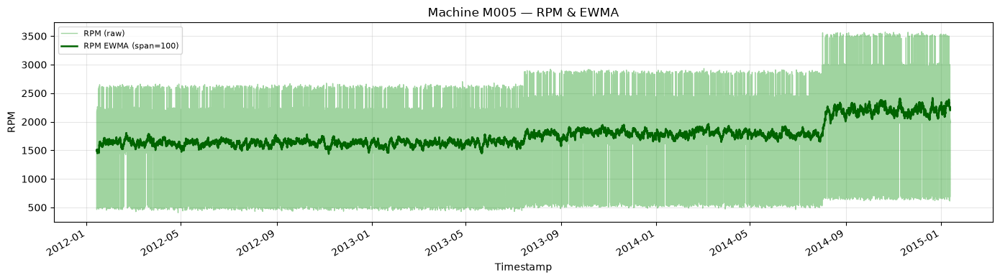

...

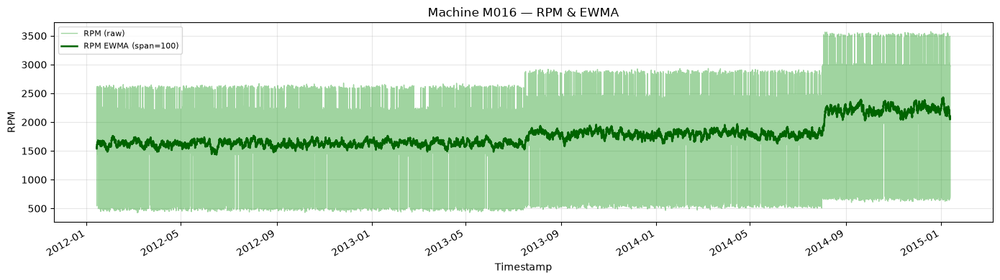

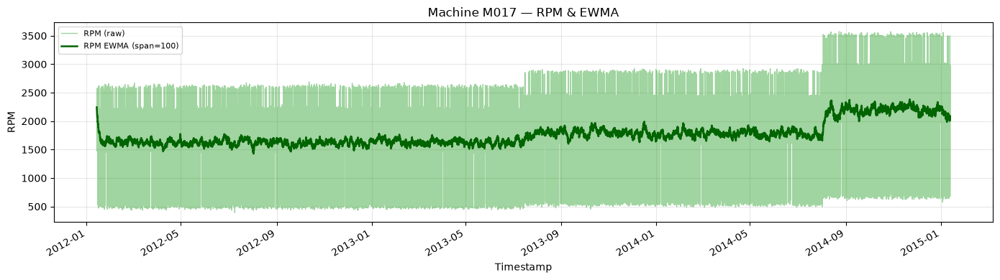

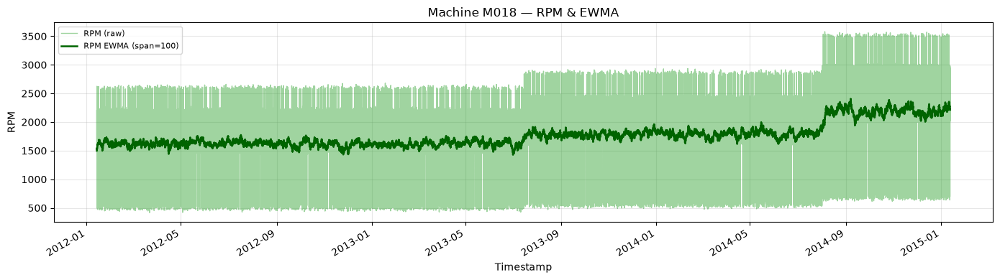

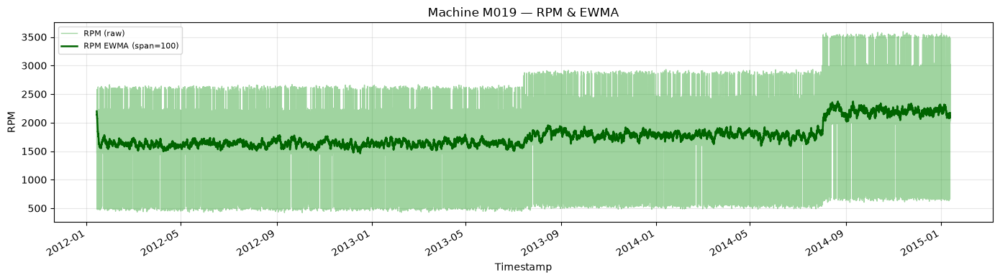

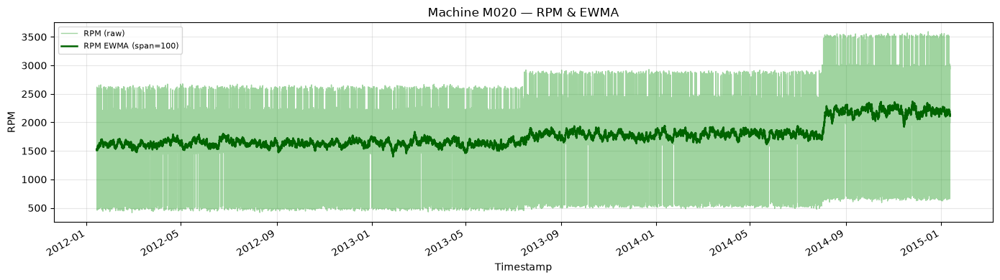

In [45]:

import numpy as np

ewm_span = 100  # adjust smoothing span as needed
for machine_id, m_df in machines.items():
  fig, ax = plt.subplots(figsize=(14, 4.0))

  rpm_ewm = m_df["rpm"].ewm(span=ewm_span, adjust=False).mean()

  ax.plot(
      m_df["timestamp"],
      m_df["rpm"],
      color="tab:green",
      linewidth=1.0,
      alpha=0.45,
      label="RPM (raw)",
  )
  ax.plot(
      m_df["timestamp"],
      rpm_ewm,
      color="darkgreen",
      linewidth=1.8,
      label=f"RPM EWMA (span={ewm_span})",
  )

  ax.set_title(f"Machine {machine_id} — RPM & EWMA")
  ax.set_xlabel("Timestamp")
  ax.set_ylabel("RPM")
  ax.grid(True, alpha=0.3)
  ax.legend(loc="upper left", fontsize=8)
  fig.autofmt_xdate()
  plt.tight_layout()
  plt.show()


The above graphs show an exponentially weighted moving average of the daily mean of rpm. It is a lot of smoothing of the data, since the moving average has a window of 10 days. There are 2 prominent jumps, the first one being about halfway through the batch, which seems to be a slight increase in the maximum that the average can reach, with barely any change in the minimum, meaning that the mean does not move much. The second jump is more prominent, with a bigger increase in maximum, and a more noticeable increase in minimum compared to the previous jump. 

However, there still a temporal pattern for these jumps, they seem to happen around july/august for each machine. Curiously, this does not happen in the first year.

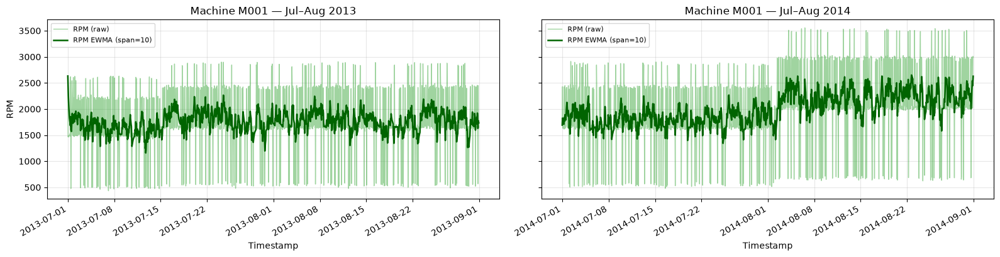

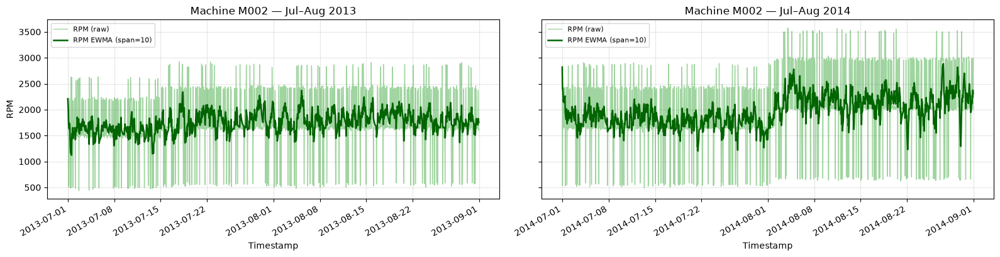

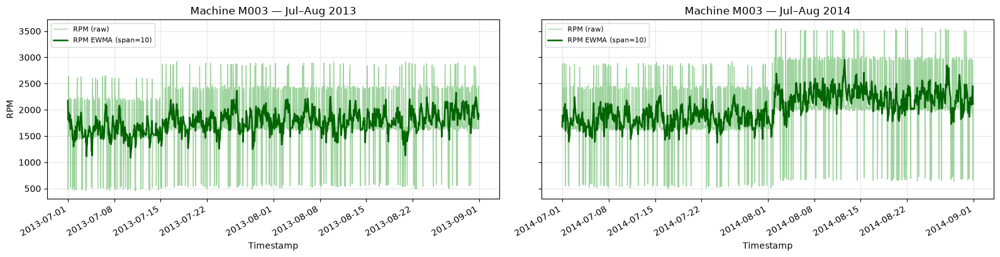

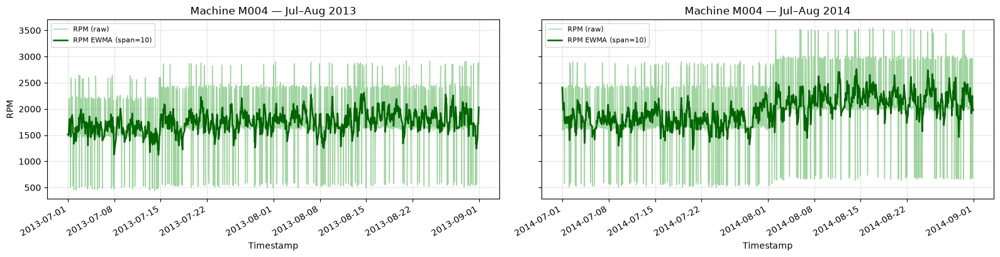

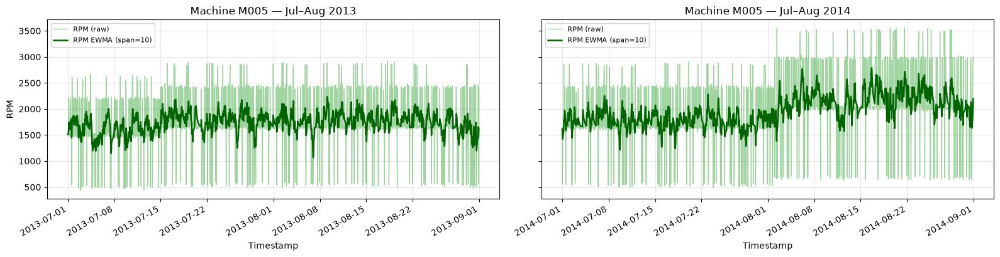

...

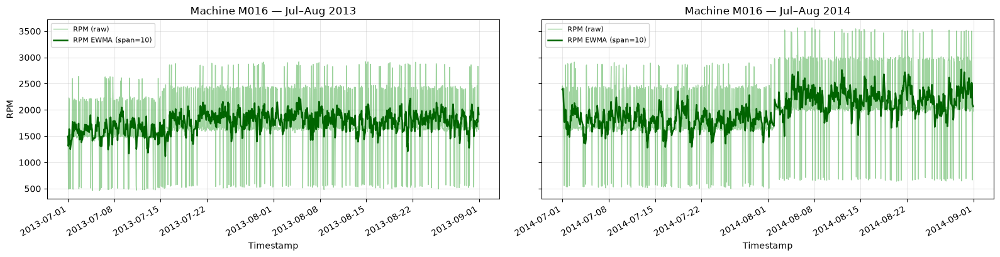

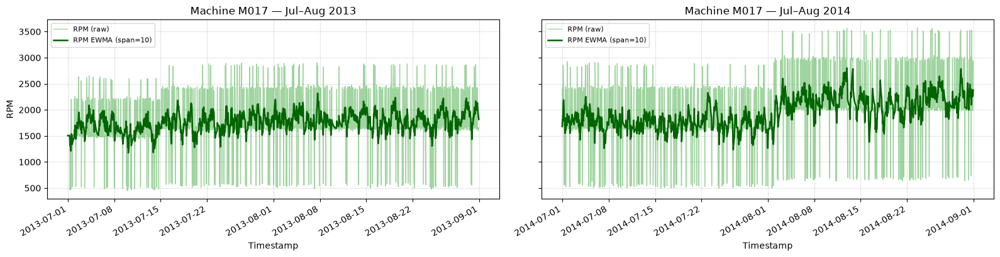

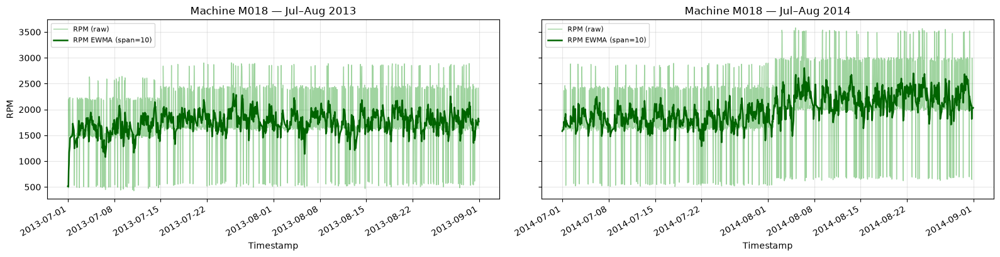

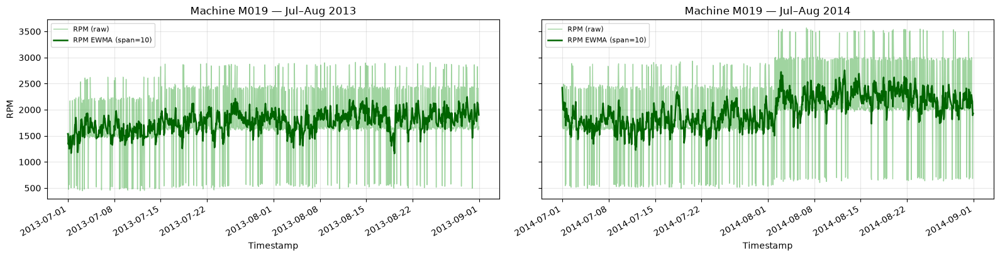

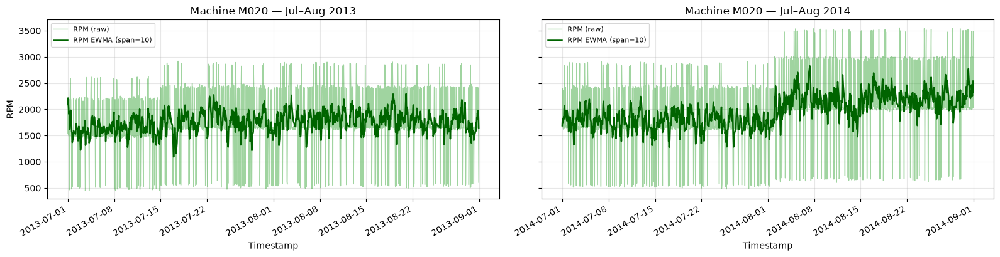

In [46]:
ewm_span = 10


def plot_rpm_two_periods(
    m_df: pd.DataFrame, machine_id: str, span: int = 10
) -> None:
  df = m_df.copy()
  df["timestamp"] = pd.to_datetime(df["timestamp"])
  df = df.set_index("timestamp").sort_index()

  periods = [
      ("2013-07-01", "2013-08-31 23:59:59", "Jul–Aug 2013"),
      ("2014-07-01", "2014-08-31 23:59:59", "Jul–Aug 2014"),
  ]

  fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 4.2), sharey=True)

  for ax, (start, end, label) in zip(axes, periods):
    sub = df.loc[start:end, "rpm"].dropna()
    rpm_ewm = sub.ewm(span=span, adjust=False).mean()

    ax.plot(
        sub.index,
        sub.values,
        color="tab:green",
        linewidth=1.0,
        alpha=0.45,
        label="RPM (raw)",
    )
    ax.plot(
        rpm_ewm.index,
        rpm_ewm.values,
        color="darkgreen",
        linewidth=1.8,
        label=f"RPM EWMA (span={span})",
    )
    ax.set_title(f"Machine {machine_id} — {label}")
    ax.set_xlabel("Timestamp")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper left", fontsize=8)

  axes[0].set_ylabel("RPM")
  fig.autofmt_xdate()
  plt.tight_layout()
  plt.show()


for machine_id, m_df in machines.items():
  plot_rpm_two_periods(m_df, machine_id, span=ewm_span)

Plotting the 2 month period where the jumps occur, it becomes more clear that they happen around the same time for each machine. However, they do not occur exactly within a year of each other. I plotted this mostly out of curiosity, I don't think this negates the idea that the jumps correspond to sensor drift. Given that there seems to be a sudden jump in both mean and standard deviation, I think the KS test would be suitable, since it would allow us to detect the different distribution of the data after the jump. I am not exactly sure whether an ML model would be helpful, or whether we can do it with a formula (sth like scaling the new batch to the baseline's standard deviation, and moving it to the mean).